# Exercice 2 - Classification : survie sur le Titanic

**Objectif** : prédire si un passager a survécu (1) ou non (0).

> Jeu de données : [Titanic (Kaggle)](https://www.kaggle.com/competitions/titanic) -> télécharger `train.csv`, le renommer en `titanic.csv` et le placer dans `data/`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

sns.set_theme(style="whitegrid")

## Étape 1 - Chargement et exploration

In [2]:
data = pd.read_csv("../data/titanic.csv")
print(data.head())
print(data.info())
print(data.isnull().sum())
print(data["Survived"].value_counts(normalize=True))

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN        S  
<c

## Étape 2 - Nettoyage et traitement

In [3]:
data = data[["Survived", "Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]].copy()
data["Age"] = data["Age"].fillna(data["Age"].median())
data["Embarked"] = data["Embarked"].fillna(data["Embarked"].mode()[0])
print(data.isnull().sum().sum(), "valeurs manquantes restantes")

0 valeurs manquantes restantes


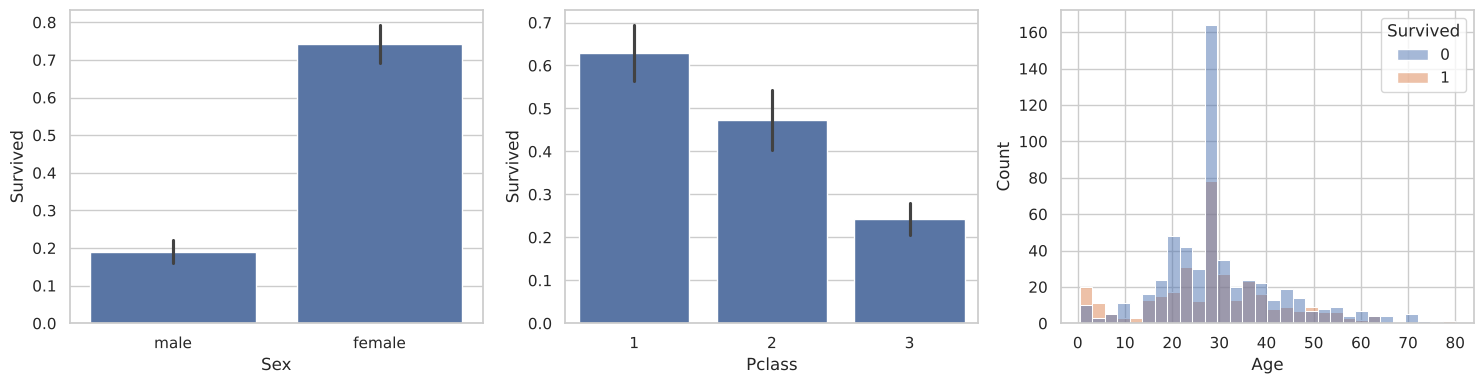

In [4]:
# Quelques graphiques exploratoires
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.barplot(data=data, x="Sex", y="Survived", ax=ax[0])
sns.barplot(data=data, x="Pclass", y="Survived", ax=ax[1])
sns.histplot(data=data, x="Age", hue="Survived", bins=30, ax=ax[2])
plt.tight_layout()
plt.show()

## Étape 3 - Encodage des variables catégorielles

In [5]:
le = LabelEncoder()
data["Sex"] = le.fit_transform(data["Sex"])
data["Embarked"] = le.fit_transform(data["Embarked"])
data.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,1,22.0,1,0,7.2500,2
1,1,1,0,38.0,1,0,71.2833,0
2,1,3,0,26.0,0,0,7.9250,2
3,1,1,0,35.0,1,0,53.1000,2
4,0,3,1,35.0,0,0,8.0500,2


> **Remarque critique** : `LabelEncoder` donne un ordre artificiel à `Embarked` (C=0, Q=1, S=2).
> Pour la régression logistique, un `One-Hot Encoding` (`pd.get_dummies`) est plus correct.
> Comparé plus bas.

## Étape 4 - Séparation des données

In [6]:
X = data.drop("Survived", axis=1)
y = data["Survived"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)

(712, 7) (179, 7)


## Étape 5 - Entraînement des modèles

In [7]:
log_model = LogisticRegression(max_iter=1000)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

log_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

## Étape 6 - Évaluation

In [8]:
y_pred_log = log_model.predict(X_test)
y_pred_rf = rf_model.predict(X_test)

print("Accuracy (Logistic)     :", round(accuracy_score(y_test, y_pred_log), 3))
print("Accuracy (Random Forest):", round(accuracy_score(y_test, y_pred_rf), 3))
print("\n--- Logistic Regression ---")
print(classification_report(y_test, y_pred_log))
print("--- Random Forest ---")
print(classification_report(y_test, y_pred_rf))

Accuracy (Logistic)     : 0.804
Accuracy (Random Forest): 0.827

--- Logistic Regression ---
              precision    recall  f1-score   support

           0       0.81      0.89      0.85       110
           1       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179

--- Random Forest ---
              precision    recall  f1-score   support

           0       0.84      0.89      0.86       110
           1       0.81      0.72      0.76        69

    accuracy                           0.83       179
   macro avg       0.82      0.81      0.81       179
weighted avg       0.83      0.83      0.82       179



## Étape 7 - Matrice de confusion

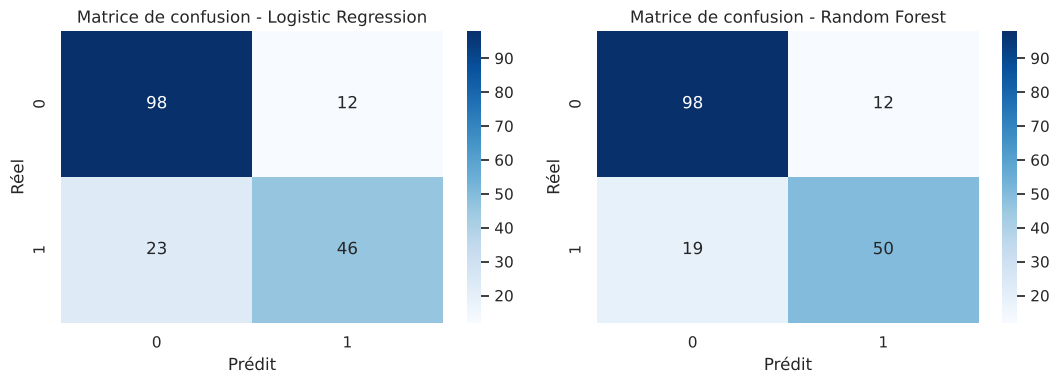

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, pred, title in zip(ax, [y_pred_log, y_pred_rf], ["Logistic Regression", "Random Forest"]):
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues", ax=a)
    a.set_title(f"Matrice de confusion - {title}")
    a.set_xlabel("Prédit")
    a.set_ylabel("Réel")
plt.tight_layout()
plt.show()

## Pour aller plus loin : validation croisée et importance des variables

Logistic       CV accuracy = 0.789 (+/- 0.017)


Random Forest  CV accuracy = 0.809 (+/- 0.034)


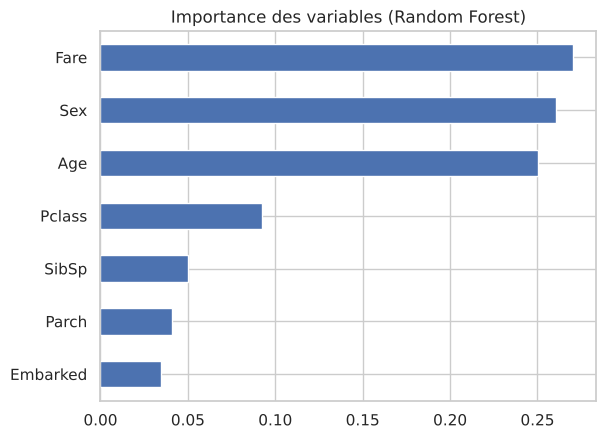

In [10]:
for name, model in [("Logistic", log_model), ("Random Forest", rf_model)]:
    scores = cross_val_score(model, X, y, cv=5, scoring="accuracy")
    print(f"{name:<14} CV accuracy = {scores.mean():.3f} (+/- {scores.std():.3f})")

pd.Series(rf_model.feature_importances_, index=X.columns).sort_values().plot.barh(title="Importance des variables (Random Forest)")
plt.show()

## Conclusion (à rédiger)

- Quel modèle retenir et pourquoi ? (accuracy, mais aussi précision/rappel de la classe « survivant »)
- Quelles variables comptent le plus ? (attendu : `Sex`, `Fare`, `Age`, `Pclass`)
- Une seule séparation train/test est instable : la validation croisée donne une estimation plus fiable.